# Assess Sampling Sufficiency

Observations sample a varying field, such as precipitation or temperature, at discrete times, and a study estimates a statistic of the field from the samples: for example, the mean precipitation at each place over a month. Whether a constellation samples a field *sufficiently* depends on more than how many samples it takes. It depends on how the samples are spread in time relative to how quickly the field changes, and, for fields with daily cycles, on the times of day they see. This example uses the methods of `tatc.analysis` that assess the sufficiency of observations to show these qualities:

* `estimate_sampling_error` predicts the error of estimating the mean of a field over a period from each target's samples, for a model of the field, with the effective number of independent samples;
* `compute_revisit_statistics` describes the times between samples, including the longest gap;
* `compute_local_time_coverage` describes the samples' times of day;
* `sample_field` and `compare_sampled_means` measure the actual errors against a simulation of the field (a nature run).

The example compares four designs of a constellation: one satellite in a sun-synchronous orbit, a train of three satellites in that orbit minutes apart, three satellites in sun-synchronous orbits of different crossing times, and one satellite in a precessing, inclined orbit. Running it requires xarray for the nature run (in addition to `tatc[examples]`, `pip install xarray`).

## The Model of a Sampled Field

`estimate_sampling_error` models the field at each target as stationary, with a standard deviation and an exponential correlation in time, `exp(-|dt| / T)`, whose decorrelation time `T` is the time over which its values become nearly independent: hours for convective precipitation, days for synoptic temperature. For this model, the variance of the error of the mean of the samples, compared with the mean of the field over the period, is exact (`sampling_error_variance`). The error is relative to the field's standard deviation (`relative_error`), or in its units (`sampling_error`) given the standard deviation.

The model's predictions show the first quality: what matters is how the samples spread in time relative to the decorrelation time. The figure gives the relative error of the monthly mean from samples evenly spaced over 30 days, for fields that decorrelate in an hour, six hours, and a day, and the error of independent samples, `1 / sqrt(n)`, often assumed.

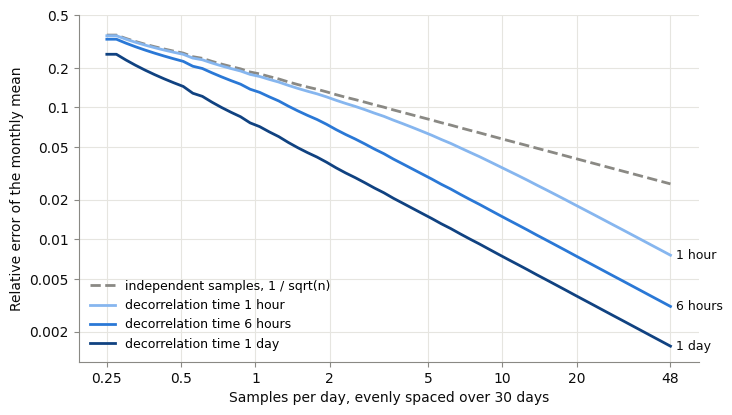

,1 hour,6 hours,1 day,independent
samples per day,,,,
0.5,0.2528,0.2235,0.1443,0.2582
2.0,0.1178,0.0722,0.0372,0.1291
8.0,0.0427,0.0186,0.0093,0.0645
24.0,0.0151,0.0062,0.0031,0.0373


In [1]:
from datetime import datetime, timedelta, timezone

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from tatc.analysis import sampling_error_variance

INK, GRAY, GRID = "#0b0b0b", "#8a8984", "#e6e5e0"
plt.rcParams.update(
    {
        "axes.edgecolor": GRAY,
        "axes.labelcolor": INK,
        "axes.titlecolor": INK,
        "xtick.color": GRAY,
        "ytick.color": GRAY,
        "xtick.labelcolor": INK,
        "ytick.labelcolor": INK,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "grid.color": GRID,
    }
)

START = datetime(2025, 7, 1, tzinfo=timezone.utc)
END = START + timedelta(days=30)
LENGTH = (END - START).total_seconds()


def evenly_spaced(per_day):
    """The times (seconds after the start) of samples evenly spaced over the period."""
    count = round(30 * per_day)
    return (np.arange(count) + 0.5) * LENGTH / count


# decorrelation times, light to dark
RAMP = {
    "1 hour": (timedelta(hours=1), "#86b6ef"),
    "6 hours": (timedelta(hours=6), "#2a78d6"),
    "1 day": (timedelta(days=1), "#104281"),
}
rates = np.geomspace(0.25, 48, 60)  # samples per day
errors = pd.DataFrame(
    {
        label: [
            np.sqrt(
                sampling_error_variance(evenly_spaced(r), LENGTH, t.total_seconds())
            )
            for r in rates
        ]
        for label, (t, _) in RAMP.items()
    },
    index=rates,
)
errors["independent"] = 1 / np.sqrt(np.round(30 * rates))

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(
    rates,
    errors["independent"],
    color=GRAY,
    lw=2,
    ls="--",
    label="independent samples, 1 / sqrt(n)",
)
for label, (_, color) in RAMP.items():
    ax.plot(
        rates, errors[label], color=color, lw=2, label=f"decorrelation time {label}"
    )
    ax.annotate(
        label,
        (rates[-1], errors[label].iloc[-1]),
        xytext=(4, 0),
        textcoords="offset points",
        va="center",
        color=INK,
        fontsize=9,
    )
ax.set(
    xscale="log",
    yscale="log",
    xlabel="Samples per day, evenly spaced over 30 days",
    ylabel="Relative error of the monthly mean",
)
ax.set_xticks(
    [0.25, 0.5, 1, 2, 5, 10, 20, 48], ["0.25", "0.5", "1", "2", "5", "10", "20", "48"]
)
ax.set_yticks(
    [0.002, 0.005, 0.01, 0.02, 0.05, 0.1, 0.2, 0.5],
    ["0.002", "0.005", "0.01", "0.02", "0.05", "0.1", "0.2", "0.5"],
)
ax.minorticks_off()
ax.grid(True, lw=0.8)
ax.legend(frameon=False, fontsize=9, loc="lower left")
plt.show()

# the errors at a few rates
pd.DataFrame(
    {
        **{
            label: [
                np.sqrt(
                    sampling_error_variance(evenly_spaced(r), LENGTH, t.total_seconds())
                )
                for r in (0.5, 2, 8, 24)
            ]
            for label, (t, _) in RAMP.items()
        },
        "independent": [1 / np.sqrt(30 * r) for r in (0.5, 2, 8, 24)],
    },
    index=pd.Index([0.5, 2, 8, 24], name="samples per day"),
).round(4)

Samples farther apart than the decorrelation time are nearly independent, and their error is about `1 / sqrt(n)`: at one sample every two days, 0.253 for a field that decorrelates in an hour, against 0.258. Samples closer together than the decorrelation time repeat each other, but they also follow the field's variations through the month, so the error of their mean falls faster than `1 / sqrt(n)`: at eight samples a day (every three hours), the error for a field that decorrelates in six hours is 0.019, against 0.065. Assuming independent samples overstates the error of dense sampling, here by more than three times.

A field that changes slowly is followed by fewer samples: at two samples a day, the error is 0.037 for a field that decorrelates in a day and 0.118 for one that decorrelates in an hour. The error is that of the mean over the period (here, the month), not of a long-term mean. The monthly mean of a slowly changing field itself differs from month to month, which the error does not include.

## Four Designs

The designs observe a grid of points from 50 deg S to 50 deg N (every 5 deg of latitude and 10 deg of longitude) over July 2025. Three carry a sounder with a 2,600 km swath at 824 km (like ATMS) in sun-synchronous orbits, which cross the equator at fixed local times; the precessing design carries a radiometer with an 885 km swath at 407 km in a 65 deg inclined orbit (like GMI on the GPM Core Observatory), whose crossing times drift through the day over about 46 days. The train's three satellites follow one another in the same orbit five minutes apart (`TrainConstellation`). The field decorrelates in six hours.

For each design, the table gives the median over the points of the samples, the effective samples, the relative error, and the error that the samples would have if they were independent, and of the revisit statistics: the mean time between samples, its median and 90th percentile, and the longest gap (including those from the start of the month to the first sample and from the last sample to the end).

In [2]:
import geopandas as gpd
from shapely.geometry import Point

from tatc.analysis import (
    collect_observations,
    compute_revisit_statistics,
    estimate_sampling_error,
)
from tatc.schemas import (
    CircularOrbit,
    Instrument,
    Satellite,
    SunSynchronousOrbit,
    TrainConstellation,
)
from tatc.utils import hash_geometry, swath_width_to_field_of_regard

LATITUDES = np.arange(-50, 51, 5)
LONGITUDES = np.arange(-180, 180, 10)
lon, lat = np.meshgrid(LONGITUDES, LATITUDES)
points = gpd.GeoDataFrame(
    geometry=[Point(x, y) for x, y in zip(lon.ravel(), lat.ravel())], crs="EPSG:4326"
)
points["target_hash"] = [hash_geometry(point) for point in points.geometry]

SOUNDER = Instrument(
    name="sounder", field_of_regard=swath_width_to_field_of_regard(824e3, 2600e3)
)
RADIOMETER = Instrument(
    name="radiometer", field_of_regard=swath_width_to_field_of_regard(407e3, 885e3)
)


def sun_synchronous(crossing):
    """A sun-synchronous orbit at 824 km with an ascending equator crossing time."""
    return SunSynchronousOrbit(
        altitude=824e3, equator_crossing_time=crossing, epoch=START
    )


train = TrainConstellation(
    name="train",
    orbit=sun_synchronous("13:30"),
    number_satellites=3,
    interval=timedelta(minutes=5),
    instruments=[SOUNDER],
)
DESIGNS = {
    "one sun-synchronous": [
        Satellite(name="13:30", orbit=sun_synchronous("13:30"), instruments=[SOUNDER])
    ],
    "train of three": train.generate_members(),
    "three sun-synchronous": [
        Satellite(name=crossing, orbit=sun_synchronous(crossing), instruments=[SOUNDER])
        for crossing in ("13:30", "17:30", "21:30")
    ],
    "precessing": [
        Satellite(
            name="precessing",
            orbit=CircularOrbit(altitude=407e3, inclination=65, epoch=START),
            instruments=[RADIOMETER],
        )
    ],
}
COLORS = dict(zip(DESIGNS, ["#2a78d6", "#eb6834", "#1baf7a", "#eda100"]))
DECORRELATION_TIME = timedelta(hours=6)

observations = {
    name: collect_observations(points, satellites, START, END)
    for name, satellites in DESIGNS.items()
}
estimates, revisits = {}, {}
for name in DESIGNS:
    estimates[name] = estimate_sampling_error(
        observations[name], START, END, DECORRELATION_TIME, targets=points
    ).set_index("target_hash")
    revisits[name] = compute_revisit_statistics(
        observations[name], START, END, targets=points
    ).set_index("target_hash")
hours = pd.Timedelta(hours=1)
pd.DataFrame(
    {
        name: {
            "satellites": len(DESIGNS[name]),
            "samples": estimates[name].samples.median(),
            "effective samples": estimates[name].effective_samples.median(),
            "relative error": estimates[name].relative_error.median(),
            "if independent": (1 / np.sqrt(estimates[name].samples)).median(),
            "mean revisit (h)": revisits[name].revisit.median() / hours,
            "median revisit (h)": revisits[name]["revisit p50"].median() / hours,
            "90th percentile revisit (h)": revisits[name]["revisit p90"].median()
            / hours,
            "longest gap (h)": revisits[name].max_gap.median() / hours,
        }
        for name in DESIGNS
    }
).T.round(3)

,satellites,samples,effective samples,relative error,if independent,mean revisit (h),median revisit (h),90th percentile revisit (h),longest gap (h)
one sun-synchronous,1.0,63.0,44.686,0.076,0.126,11.417,12.421,12.425,14.041
train of three,3.0,189.0,45.109,0.075,0.073,3.766,0.083,12.257,13.874
three sun-synchronous,3.0,189.0,57.530,0.029,0.073,3.807,3.387,5.049,5.653
precessing,1.0,25.0,22.203,0.169,0.200,27.640,23.126,51.289,57.615


The count of samples does not rank the designs. The train takes three times the samples of one satellite (189 against 63 at the median point), but its error is the same (0.075 against 0.076): its satellites pass each point within minutes, and samples minutes apart repeat each other entirely. The three sun-synchronous satellites take the same 189 samples spread through the day, and cut the error by 2.6 times (0.029). The precessing satellite, with a narrower swath, takes 25 samples and has the largest error (0.169).

The effective number of samples (`effective_samples`, the number of independent samples whose mean would vary as much as the mean of the samples) shows the repetition: the train's 189 samples are worth 45.1 independent samples, as one satellite's 63 are worth 44.7. It is not itself the error. The three sun-synchronous satellites' samples are worth 57.5 independent samples, but their error (0.029) is much smaller than that of 57.5 independent samples (0.13), as their samples follow the field's variations through the month.

The revisit statistics show why. The mean revisit hides the clustering: the train's is 3.8 hours, as is that of the three sun-synchronous satellites. Its median revisit is five minutes and its 90th percentile 12.3 hours, and its longest gap (13.9 hours) is that of one satellite. The three sun-synchronous satellites revisit every 3.4 hours at the median, and their longest gap (5.7 hours) is shorter than the decorrelation time. The samples of one point over three days:

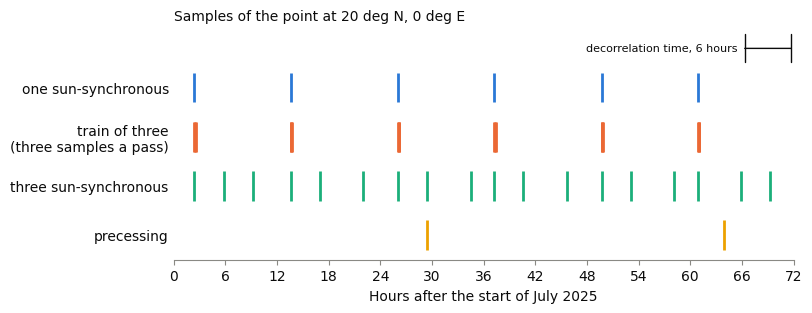

In [3]:
# the samples of one point over the first three days
point = points.set_index("target_hash").geometry
where = point[(point.x == 0) & (point.y == 20)].index[0]
fig, ax = plt.subplots(figsize=(8, 3))
for row, name in enumerate(DESIGNS):
    samples = observations[name][observations[name].target_hash == where]
    times = (pd.to_datetime(samples.epoch) - pd.Timestamp(START)) / hours
    times = times[times < 72]
    ax.vlines(times, row - 0.3, row + 0.3, color=COLORS[name], lw=2)
labels = {name: name for name in DESIGNS} | {
    "train of three": "train of three\n(three samples a pass)"
}
ax.set_yticks(range(len(DESIGNS)), list(labels.values()))
ax.set(
    xlim=(0, 72), xticks=range(0, 73, 6), xlabel="Hours after the start of July 2025"
)
ax.tick_params(axis="y", length=0)
ax.spines["left"].set_visible(False)
# the decorrelation time, for scale
ax.annotate(
    "",
    xy=(66, -0.8),
    xytext=(72, -0.8),
    arrowprops={"arrowstyle": "|-|", "color": INK, "lw": 1},
)
ax.text(
    65.5,
    -0.8,
    "decorrelation time, 6 hours",
    ha="right",
    va="center",
    color=INK,
    fontsize=8,
)
ax.set_ylim(len(DESIGNS) - 0.5, -1.2)
ax.set_title("Samples of the point at 20 deg N, 0 deg E", loc="left", fontsize=10)
plt.show()

The sun-synchronous satellite passes the point twice a day, about 12 hours apart, and the train at the same times. The three sun-synchronous satellites pass about every four hours, and the precessing satellite twice in three days.

## Local Time of Day

A field with a daily cycle, such as afternoon convection, needs samples across the times of day; a stationary model has none. `compute_local_time_coverage` counts each target's samples in intervals of local (mean solar) time. The table gives the share of each design's samples in each 3-hour interval, over all points, and the median number of intervals each point is sampled in.

In [4]:
from tatc.analysis import compute_local_time_coverage

coverage = {
    name: compute_local_time_coverage(observations[name], targets=points)
    for name in DESIGNS
}
bins = [
    column
    for column in coverage["precessing"].columns
    if column.startswith("local ") and ":" in column
]
table = pd.DataFrame(
    {name: 100 * c[bins].sum() / c[bins].sum().sum() for name, c in coverage.items()}
).T
table["median intervals sampled"] = [
    c.local_bins_sampled.median() for c in coverage.values()
]
table.round(1)

,local 00:00,local 03:00,local 06:00,local 09:00,local 12:00,local 15:00,local 18:00,local 21:00,median intervals sampled
one sun-synchronous,47.9,1.0,0.0,1.0,47.9,1.1,0.0,1.1,2.0
train of three,47.8,1.3,0.0,0.8,47.8,1.4,0.0,0.8,2.0
three sun-synchronous,16.0,13.1,7.8,13.1,16.0,13.1,7.8,13.1,8.0
precessing,17.1,11.7,6.2,14.9,17.0,11.9,6.3,14.9,7.0


The sun-synchronous satellite and the train sample each point at two local times, 12 hours apart: 96% of their samples are in the intervals from 00:00 and 12:00 (its crossings at 01:30 and 13:30). The three sun-synchronous satellites sample every interval, though unevenly (8 to 16% of their samples in each). The precessing satellite's crossing times drift through the day, so over the month it samples seven of the eight intervals at the median point.

## Testing the Estimate with a Nature Run

A nature run is a simulation of the field, from which the samples of a design are taken at the times and places of its observations (`sample_field`) and compared with the true mean of the field over the period (`compare_sampled_means`). Here the nature run is synthetic: at each point, a series of half-hourly values over the month that follows the model exactly (a first-order Markov process with a standard deviation of 1 and a decorrelation time of six hours), independent between points. A second version adds a daily cycle peaked at 16:00 local time, as of afternoon convection, whose standard deviation is half that of the random variations.

In [5]:
import xarray as xr

STEP = timedelta(minutes=30)
times = pd.date_range(START, END, freq=STEP, inclusive="left").tz_convert(None)
shape = (len(times), len(LATITUDES), len(LONGITUDES))
rng = np.random.default_rng(2025)
correlation = np.exp(-STEP / DECORRELATION_TIME)  # between consecutive half-hours
anomaly = np.empty(shape)
anomaly[0] = rng.standard_normal(shape[1:])
for k in range(1, len(times)):
    anomaly[k] = correlation * anomaly[k - 1] + np.sqrt(
        1 - correlation**2
    ) * rng.standard_normal(shape[1:])


def peaked(hour):
    """A daily cycle peaked at 16:00 local time."""
    return np.exp(2 * np.cos(2 * np.pi * (hour - 16) / 24))


day = np.linspace(0, 24, 1440, endpoint=False)
local_hour = (times.hour + times.minute / 60).to_numpy()[
    :, None, None
] + LONGITUDES / 15
cycle = 0.5 * (peaked(local_hour) - peaked(day).mean()) / peaked(day).std()
FIELDS = {
    name: xr.DataArray(
        values,
        coords={"time": times, "lat": LATITUDES, "lon": LONGITUDES},
        dims=("time", "lat", "lon"),
        name="value",
    )
    for name, values in {"stationary": anomaly, "daily cycle": anomaly + cycle}.items()
}

The values of the nature run at the point of the earlier figure (20 deg N, 0 deg E) over the first three days show what its decorrelation time means, with the samples of the sun-synchronous satellites there: the 13:30 satellite is the one sun-synchronous design, and with the 17:30 and 21:30 satellites, the three.

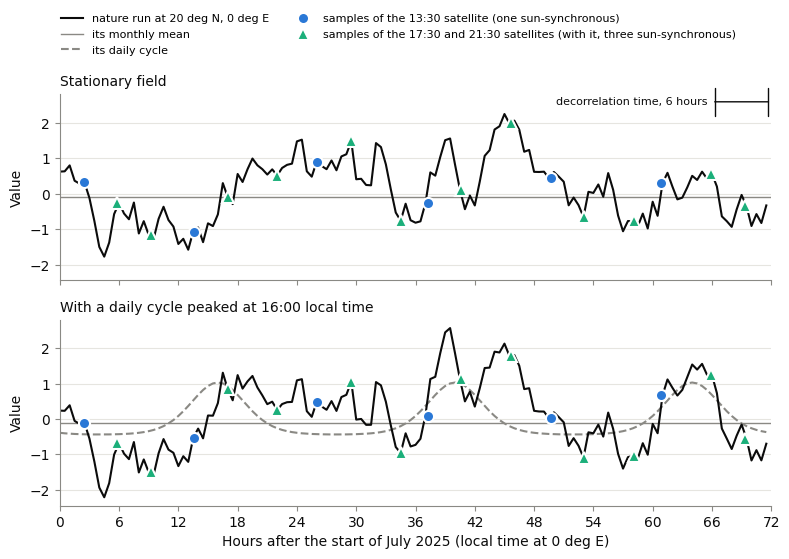

In [6]:
from tatc.analysis import sample_field

# the values over the first three days, with the samples of the sun-synchronous satellites
elapsed = (times - times[0]) / hours
shown = elapsed < 72
three = observations["three sun-synchronous"]
three = three[three.target_hash == where]
SAMPLES = {
    "samples of the 13:30 satellite (one sun-synchronous)": (
        three[three.satellite == "13:30"],
        COLORS["one sun-synchronous"],
        "o",
    ),
    "samples of the 17:30 and 21:30 satellites (with it, three sun-synchronous)": (
        three[three.satellite != "13:30"],
        COLORS["three sun-synchronous"],
        "^",
    ),
}
TITLES = {
    "stationary": "Stationary field",
    "daily cycle": "With a daily cycle peaked at 16:00 local time",
}
fig, axes = plt.subplots(2, 1, figsize=(8, 5.6), sharex=True, sharey=True)
for ax, (field, values) in zip(axes, FIELDS.items()):
    series = values.sel(lat=20, lon=0)
    ax.axhline(float(series.mean()), color=GRAY, lw=1)
    if field == "daily cycle":
        daily = series - FIELDS["stationary"].sel(lat=20, lon=0)
        ax.plot(elapsed[shown], daily.values[shown], color=GRAY, lw=1.5, ls="--")
    ax.plot(elapsed[shown], series.values[shown], color=INK, lw=1.5)
    for samples, color, marker in SAMPLES.values():
        sampled = sample_field(samples, values)
        at = (pd.to_datetime(sampled.epoch) - pd.Timestamp(START)) / hours
        ax.plot(
            at[at < 72],
            sampled.value[at < 72],
            ls="none",
            marker=marker,
            ms=8 if marker == "o" else 9,
            color=color,
            markeredgecolor="white",
            markeredgewidth=1.5,
        )
    ax.set_title(TITLES[field], loc="left", fontsize=10)
    ax.set_ylabel("Value")
    ax.grid(True, axis="y", lw=0.8)
# the decorrelation time, for scale
axes[0].annotate(
    "",
    xy=(66, 2.6),
    xytext=(72, 2.6),
    arrowprops={"arrowstyle": "|-|", "color": INK, "lw": 1},
)
axes[0].text(
    65.5,
    2.6,
    "decorrelation time, 6 hours",
    ha="right",
    va="center",
    color=INK,
    fontsize=8,
)
axes[1].set(
    xlim=(0, 72),
    xticks=range(0, 73, 6),
    xlabel="Hours after the start of July 2025 (local time at 0 deg E)",
)
handles = [
    plt.Line2D([], [], color=INK, lw=1.5, label="nature run at 20 deg N, 0 deg E"),
    plt.Line2D([], [], color=GRAY, lw=1, label="its monthly mean"),
    plt.Line2D([], [], color=GRAY, lw=1.5, ls="--", label="its daily cycle"),
] + [
    plt.Line2D(
        [],
        [],
        ls="none",
        marker=marker,
        ms=8,
        color=color,
        markeredgecolor="white",
        markeredgewidth=1.5,
        label=label,
    )
    for label, (_, color, marker) in SAMPLES.items()
]
fig.legend(
    handles=handles,
    loc="upper left",
    ncol=2,
    frameon=False,
    fontsize=8,
    bbox_to_anchor=(0.07, 1.0),
)
fig.tight_layout(rect=(0, 0, 1, 0.9))
plt.show()

The field wanders above and below its monthly mean over hours. Its values half an hour apart are nearly the same (a correlation of 0.92), values six hours apart are loosely related (0.37, or `exp(-1)`), and values a day apart are nearly independent (0.02). The 13:30 satellite's samples, 11 to 13 hours apart, are nearly independent of each other, but they miss the variations between them, such as the rise to 2 near 45 hours; the train's three samples a pass, minutes apart, would repeat each of them. With the 17:30 and 21:30 satellites, the samples are 3 to 5 hours apart and follow the variations.

With the daily cycle, the 13:30 satellite sees the cycle near its trough (at 01:30 local time) and on its rise (at 13:30), never at its peak. The two average 0.06 above the cycle's mean, so the satellite's monthly means are biased high. The three satellites see the cycle at six times of day.

The predictions use the model's standard deviation (1) and decorrelation time in both cases, as a study would from the field's random variations. If the predictions hold, the actual errors divided by the predicted ones (the standardized errors) have a root mean square of 1, and 95% of them are within 2. The table gives these for each design and field, with the root mean square of the predicted and actual errors and the mean error.

In [7]:
from tatc.analysis import compare_sampled_means


def compare(field, name):
    """The actual and predicted errors of the monthly means of the points a design observes."""
    sampled = sample_field(observations[name], field)
    actual = compare_sampled_means(
        sampled, field, START, END, targets=points
    ).set_index("target_hash")
    predicted = estimate_sampling_error(
        observations[name], START, END, DECORRELATION_TIME, 1.0, targets=points
    )
    merged = actual.join(predicted.set_index("target_hash")[["sampling_error"]])
    merged = merged[merged.samples > 0]
    merged["standardized"] = merged.error / merged.sampling_error
    return merged


compared = {
    (field, name): compare(FIELDS[field], name) for field in FIELDS for name in DESIGNS
}
results = pd.DataFrame(
    {
        key: {
            "points": len(m),
            "predicted RMS error": np.sqrt((m.sampling_error**2).mean()),
            "actual RMS error": np.sqrt((m.error**2).mean()),
            "RMS standardized error": np.sqrt((m.standardized**2).mean()),
            "within 2 predicted (%)": 100 * (m.standardized.abs() <= 2).mean(),
            "mean error": m.error.mean(),
        }
        for key, m in compared.items()
    }
).T
results.index.names = ["field", "design"]
results.round(3)

points  predicted RMS error  \
field       design                                               
stationary  one sun-synchronous     756.0                0.076   
            train of three          756.0                0.075   
            three sun-synchronous   756.0                0.029   
            precessing              756.0                0.162   
daily cycle one sun-synchronous     756.0                0.076   
            train of three          756.0                0.075   
            three sun-synchronous   756.0                0.029   
            precessing              756.0                0.162   

                                   actual RMS error  RMS standardized error  \
field       design                                                            
stationary  one sun-synchronous               0.077                   1.015   
            train of three                    0.076                   1.015   
            three sun-synchronous             0.028                   0.968   
            precessing                        0.163                   1.013   
daily cycle one sun-synchronous               0.115                   1.515   
            train of three                    0.121                   1.616   
            three sun-synchronous             0.030                   1.033   
            precessing                        0.193                   1.282   

                                   within 2 predicted (%)  mean error  
field       design                                                     
stationary  one sun-synchronous                    94.577       0.003  
            train of three                         94.577       0.004  
            three sun-synchronous                  96.429       0.001  
            precessing                             95.767      -0.002  
daily cycle one sun-synchronous                    81.217       0.057  
            train of three                         77.646       0.069  
            three sun-synchronous                  94.841       0.001  
            precessing                             87.566      -0.000

When the field follows the model, the predictions hold for every design: the root mean square of the standardized errors is 0.97 to 1.02, 95 to 96% of the errors are within 2 predicted standard deviations, and the mean errors are near zero. This includes the train, whose samples repeat each other, and the precessing satellite, whose samples are few and irregular: the estimate accounts for the times of the samples, whatever their pattern.

The daily cycle does not change the predictions, which model a stationary field, but it changes the errors of the designs that sample few local times. The sun-synchronous satellite's monthly means are too high by 0.057 on average, as its local times of sampling suggest, and its errors are 1.5 times those predicted. The train's are 1.6 times those predicted. The precessing satellite's means are not biased on average, but each point is sampled at different local times, and its errors are 1.3 times those predicted. The three sun-synchronous satellites sample every local time, and their predictions still hold (1.03).

The predicted and actual errors of each design, for the stationary field (filled) and with the daily cycle (hollow):

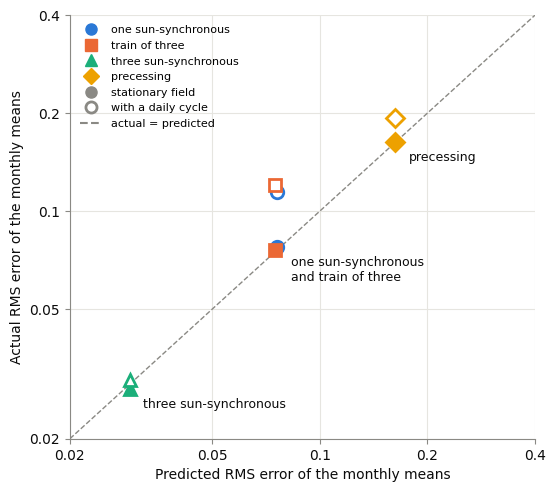

In [8]:
MARKERS = dict(zip(DESIGNS, ["o", "s", "^", "D"]))
fig, ax = plt.subplots(figsize=(6, 5.5))
limits = (0.02, 0.4)
ax.plot(limits, limits, color=GRAY, lw=1, ls="--", label="actual = predicted")
for name in DESIGNS:
    for field, filled in (("stationary", True), ("daily cycle", False)):
        row = results.loc[(field, name)]
        ax.plot(
            row["predicted RMS error"],
            row["actual RMS error"],
            marker=MARKERS[name],
            ms=9,
            ls="none",
            color=COLORS[name],
            markerfacecolor=COLORS[name] if filled else "white",
            markeredgewidth=2,
        )
# direct labels at the stationary points (one sun-synchronous satellite and the train coincide)
LABELS = {
    "one sun-synchronous": "one sun-synchronous\nand train of three",
    "three sun-synchronous": "three sun-synchronous",
    "precessing": "precessing",
}
for name, label in LABELS.items():
    ax.annotate(
        label,
        (
            results.loc[("stationary", name), "predicted RMS error"],
            results.loc[("stationary", name), "actual RMS error"],
        ),
        xytext=(10, -6),
        textcoords="offset points",
        va="top",
        color=INK,
        fontsize=9,
    )
# legend: the designs by marker and color, and the fields by fill
handles = [
    plt.Line2D(
        [], [], marker=MARKERS[name], ls="none", ms=8, color=COLORS[name], label=name
    )
    for name in DESIGNS
]
handles += [
    plt.Line2D(
        [], [], marker="o", ls="none", ms=8, color=GRAY, label="stationary field"
    ),
    plt.Line2D(
        [],
        [],
        marker="o",
        ls="none",
        ms=8,
        color=GRAY,
        markerfacecolor="white",
        markeredgewidth=2,
        label="with a daily cycle",
    ),
    plt.Line2D([], [], color=GRAY, ls="--", label="actual = predicted"),
]
ax.legend(handles=handles, frameon=False, fontsize=8, loc="upper left")
ax.set(
    xscale="log",
    yscale="log",
    xlim=limits,
    ylim=limits,
    xlabel="Predicted RMS error of the monthly means",
    ylabel="Actual RMS error of the monthly means",
)
ticks = [0.02, 0.05, 0.1, 0.2, 0.4]
ax.set_xticks(ticks, [str(t) for t in ticks])
ax.set_yticks(ticks, [str(t) for t in ticks])
ax.minorticks_off()
ax.grid(True, lw=0.8)
plt.show()

## Summary

* **Spread, not count.** The error of a sampled mean depends on how the samples spread in time relative to the field's decorrelation time. Samples minutes apart add almost nothing (the train), and samples spread within the decorrelation time reduce the error faster than independent samples would (the three sun-synchronous satellites). Rank designs by `estimate_sampling_error` rather than by their samples or mean revisit.
* **Revisits explain it.** The mean revisit hides clusters of samples; the quantiles of the revisits and the longest gap (`compute_revisit_statistics`) show them.
* **Calibrated for its model.** The estimate is exact for a stationary field with an exponential correlation. When a field follows it, the predicted errors hold for any pattern of samples.
* **Daily cycles.** A field with a daily cycle sampled at few local times has biased means and errors larger than predicted. Check the local times of the samples (`compute_local_time_coverage`) for such fields.

The predictions need the field's standard deviation and decorrelation time, which may differ between targets (mappings by `target_hash`, such as a field that decorrelates faster over land). A study takes them from climatology or another period. The validation notebook `ValidateSamplingErrorIMERG` tests this with real precipitation: the statistics of one month predict the errors of the next, and the daily cycle makes the errors of one sun-synchronous satellite up to 25% larger than predicted. The trade space examples (from `SearchTradeSpace`) use the relative error in an objective: the share of points whose daily means a design estimates within half the field's standard deviation.